In [1]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange
from matplotlib import pyplot as plt

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.uoro import UOROModel

%load_ext autoreload
%autoreload 2

In [2]:
device = 'cpu'
# model = create_agent(cf, device)
# memories = create_memories(model.actor, cf.num_envs, device=device)
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# model.train()
# 1
model = UOROModel(3, 10, 3, 1e-3, device)
model.initialize_state(device)

In [3]:
import numpy as np


def one_hot_encode(value, n_class):
    vec = np.zeros([n_class])
    vec[value] = 1
    return vec


def one_hot_decode(encoded_seq):
    return [np.argmax(vector) for vector in encoded_seq]


def get_an_bn_array(num_data, k, l):
    """
    modified from https://github.com/petered/uoro-demo
    """
    x = np.zeros([num_data], dtype=int)

    i = 0
    while i < num_data:
        n = np.random.randint(low=k, high=l+1)
        x[i:i+n] = 1
        x[i+n+1: i+2*n+1] = 2
        i += 2*n + 2
    return x


def generate_anbn_data(num_data, k=1, l=4, num_class=3):
    X_arr = get_an_bn_array(num_data+1, k, l)
    X = np.zeros([1, num_data, num_class])
    Y = np.zeros([1, num_data, num_class])
    for i in range(num_data):
        X[0, i] = one_hot_encode(X_arr[i], num_class)
        Y[0, i] = one_hot_encode(X_arr[i+1], num_class)
    return X, Y


X, Y = generate_anbn_data(10000, k=1, l=4, num_class=3)
X = torch.from_numpy(X).float().to(device)
Y = torch.from_numpy(np.argmax(Y, axis=2)).long().to(device)

In [8]:
x=torch.randn(1, 1, 3, device=device)
y=torch.ones(1, 1, device=device)
model.forward(x, y)

RuntimeError: 0D or 1D target tensor expected, multi-target not supported

In [9]:
loss_all=[]

In [12]:
l = []
loss_acc=0
for iter_id in range(20000):
    x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3])
    y_t = Y[:, iter_id:(iter_id+1)].reshape([1])

    loss, _, _, _ = model.forward(x_t, y_t)
    loss_all.append(loss)
    loss_acc += loss
    if iter_id%1000 == 0:
        print(loss_acc)
        loss_acc=0

1.139692783355713


356.0347643796704
331.37723574670963
296.15714458559523
296.5631667357957


KeyboardInterrupt: 

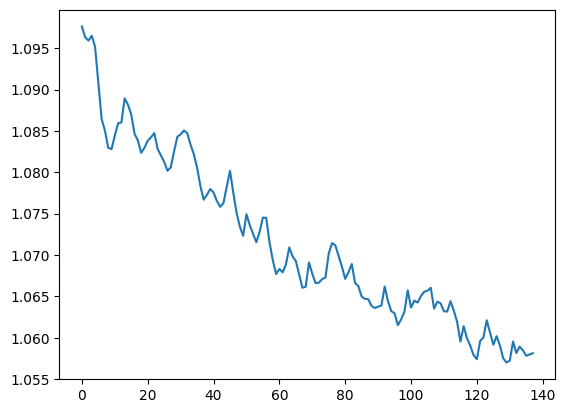

In [13]:
# plt.plot(loss_all)
h=100
plt.plot([sum(loss_all[i: i+h])/h for i in range(int(len(loss_all)/h))])
plt.show()

In [88]:
torch.tensor(loss_all)[:5000].mean()

tensor(4.0921)